In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pathlib import Path
from utils import  plot_spatial_kernel_hex
from utils.spatial_RF import compute_kernel
from utils.plotting import plot_example_RFs, plot_kernels_on_eye, receptive_fields_grid


pd.set_option('display.max_rows', 200)

In [2]:
data_dir = Path('results/connectome')

edges       = pd.read_feather(data_dir / 'edgelist_OL_columnar_T4T5norm.feather')
nodes_df    = pd.read_feather(data_dir / 'nodes_OL_columnar_T4T5norm.feather')

# edges       = pd.read_feather(data_dir / 'edgelist_OL_columnar.feather')
# nodes_df    = pd.read_feather(data_dir / 'nodes_OL_columnar.feather')
print("Available celltypes")
print("Number: ", nodes_df['cell_type'].nunique())
print(nodes_df['cell_type'].unique())

Available celltypes
Number:  24
['C2' 'C3' 'L1' 'L2' 'L3' 'L5' 'Mi1' 'Mi4' 'Mi9' 'T1' 'Tm1' 'Tm2' 'Tm20'
 'Tm4' 'Tm9' 'T4a' 'T4b' 'T4c' 'T4d' 'T5a' 'T5b' 'T5c' 'T5d' 'CT1']


- (dp, dq) = where the postsynaptic cell is relative to the input
- (-dp, -dq) = where the input is relative to the postsynaptic cell

## Example and mean kernels

In [3]:
mean_kernel, full_kernels = compute_kernel(
    edges,
    pre_type="CT1",
    post_type="T5b")

full_kernels

,post,target_p,target_q,post_side,dp,dq,count,signed_count,source_p,source_q,pre_cell_type,post_cell_type
0,98389,6.0,-10.0,right,-2,-2,0.0,0.0,4.0,-12.0,CT1,T5b
1,98389,6.0,-10.0,right,-2,-1,0.0,0.0,4.0,-11.0,CT1,T5b
2,98389,6.0,-10.0,right,-2,0,0.0,0.0,4.0,-10.0,CT1,T5b
3,98389,6.0,-10.0,right,-1,-2,0.0,0.0,5.0,-12.0,CT1,T5b
4,98389,6.0,-10.0,right,-1,-1,0.0,0.0,5.0,-11.0,CT1,T5b
...,...,...,...,...,...,...,...,...,...,...,...,...
16411,160169,-14.0,-3.0,right,1,1,0.0,0.0,-13.0,-2.0,CT1,T5b
16412,160169,-14.0,-3.0,right,1,2,0.0,0.0,-13.0,-1.0,CT1,T5b
16413,160169,-14.0,-3.0,right,2,0,0.0,0.0,-12.0,-3.0,CT1,T5b
16414,160169,-14.0,-3.0,right,2,1,0.0,0.0,-12.0,-2.0,CT1,T5b


/home/guardomayas/NUIN/sjbcs/male_cns_var/utils/plotting.py:266: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.88, 1]) #[left, bottom, right, top]


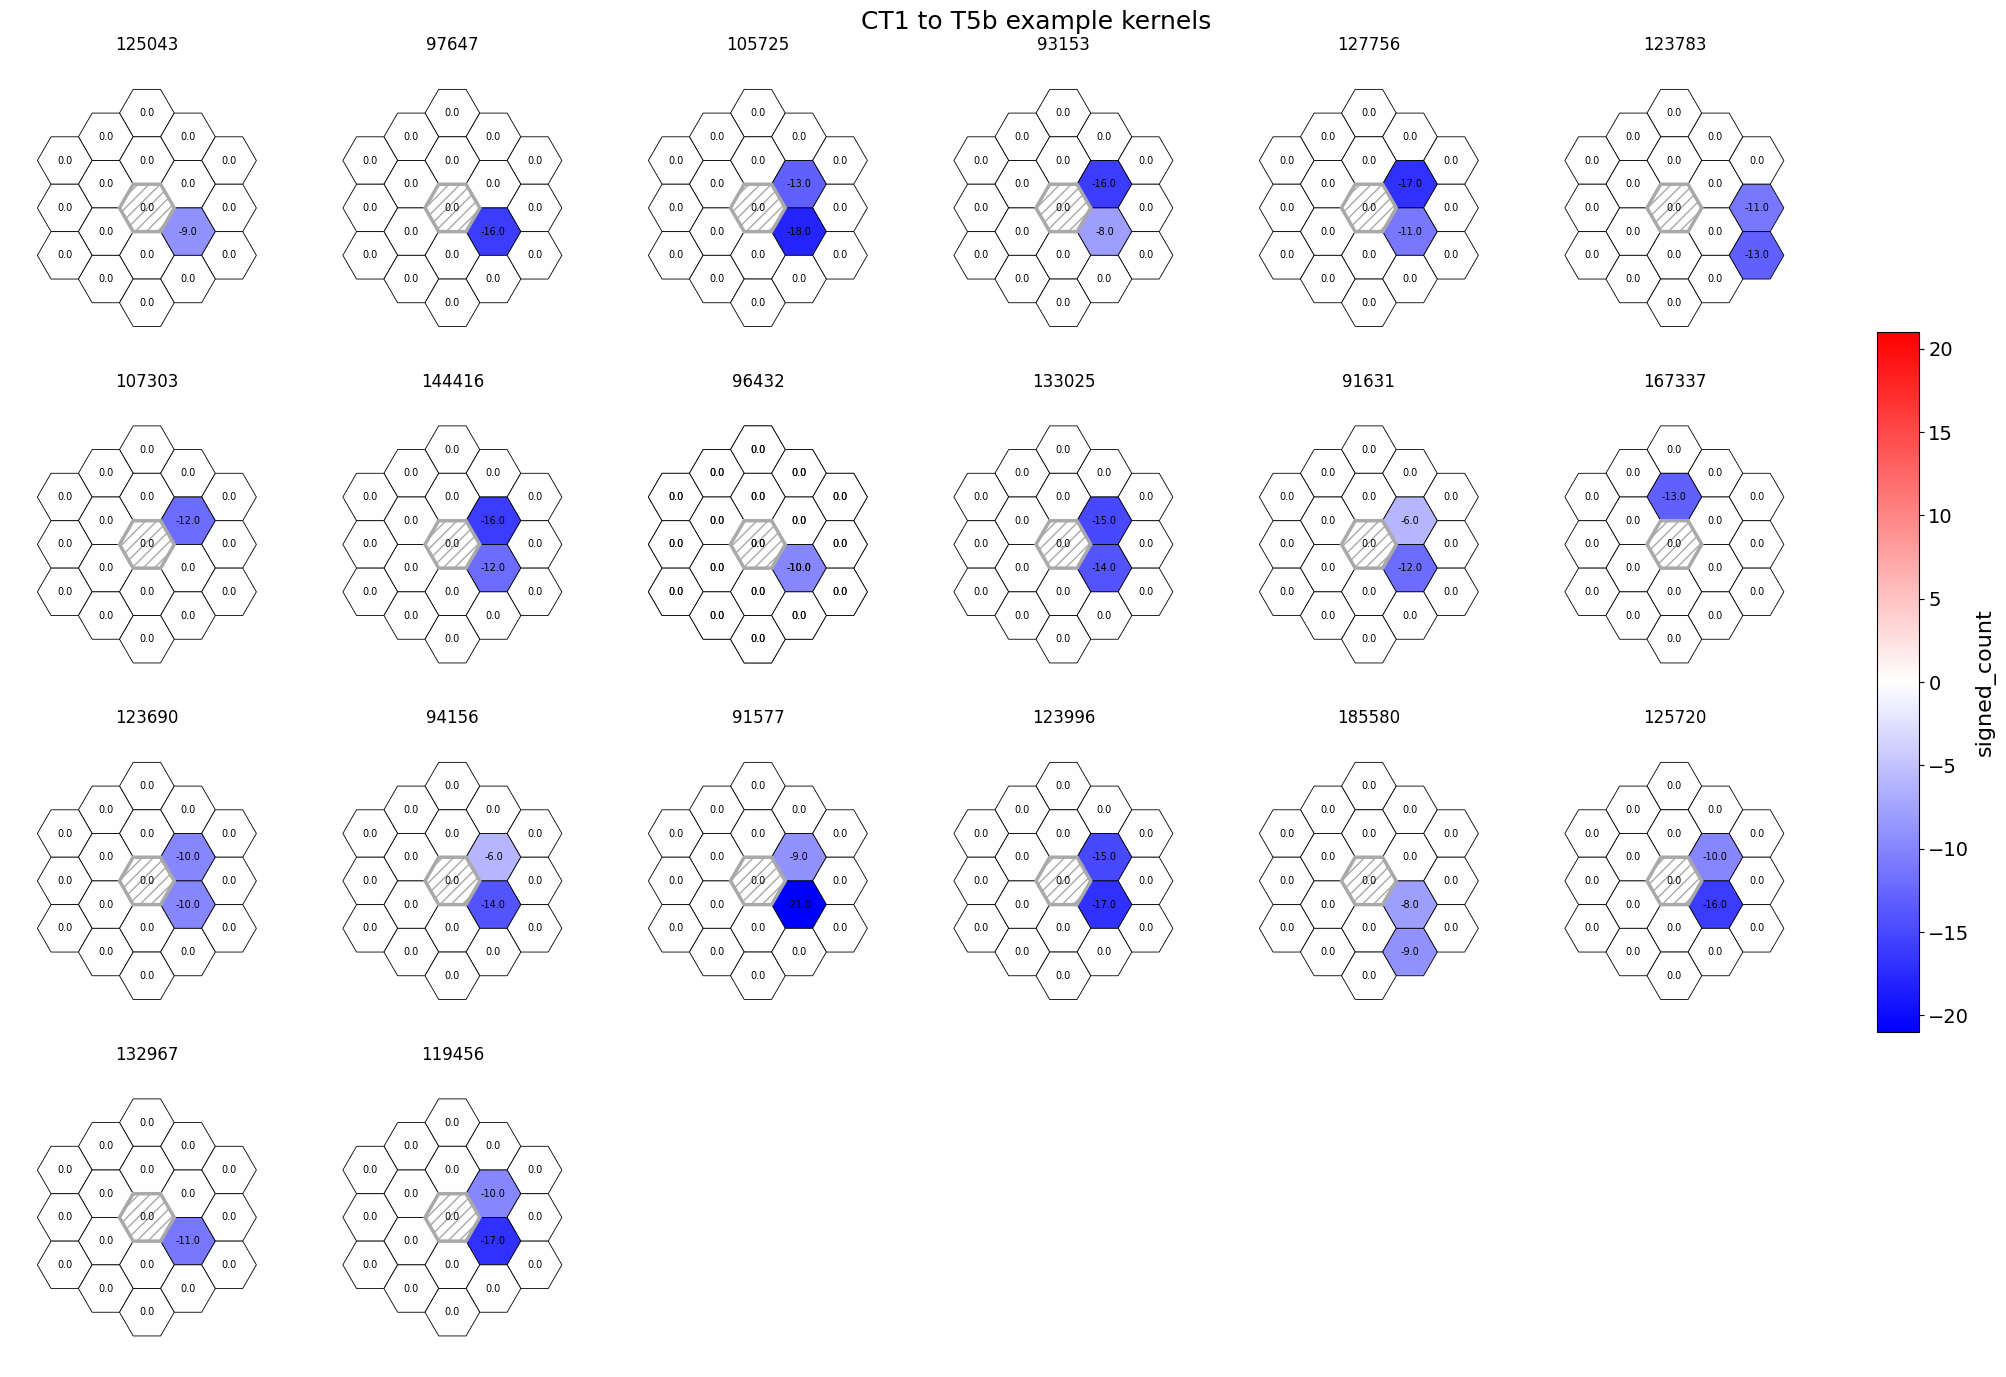

In [4]:
n_samples = 20
plot_example_RFs(full_kernels, 
                n_samples = n_samples,
                max_cols = 6
                 )

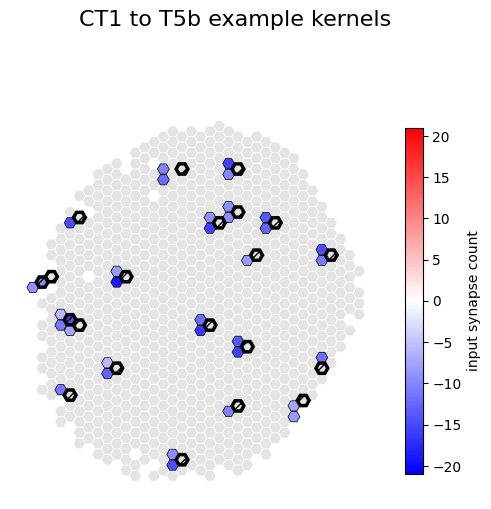

In [5]:
plot_kernels_on_eye(full_kernels, n_samples, size=(6,6),
                    seed=1)

<Axes: title={'center': 'CT1 to T5b mean kernel'}>

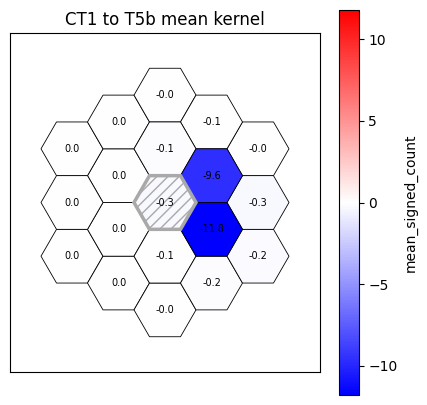

In [6]:
plot_spatial_kernel_hex(mean_kernel, value_col="mean_signed_count", 
                        radius=2, 
                        add_colorbar=True, 
                        title= f"{full_kernels['pre_cell_type'].iloc[0]} to "
    f"{full_kernels['post_cell_type'].iloc[0]} mean kernel")

## Mean kernels for a given post type

In [7]:
POST_TYPE = "T4b"
RADIUS    = 3
THRESHOLD = 2.5
VALUE_COL = "mean_signed_count"

kernels = {}
POST_TYPE_inputs = df = edges.query(
        "post_cell_type == @POST_TYPE"
    ).copy()
input_types = POST_TYPE_inputs['pre_cell_type'].unique()

for pre_type in input_types:
    mean_kernel, full = compute_kernel(
        edges,
        pre_type=pre_type,
        post_type=POST_TYPE,
        radius=RADIUS
    )
    kernels[pre_type] = mean_kernel

kernel_strength = {
    pre_type: kernels[pre_type][VALUE_COL].abs().max()
    for pre_type in input_types
}
### Filter out connections below threshold
input_types = [
    pre_type
    for pre_type in input_types
    if kernel_strength[pre_type] >= THRESHOLD
]

input_types = sorted(
    input_types,
    key=lambda pre_type: kernel_strength[pre_type],
    reverse=True
)

/home/guardomayas/NUIN/sjbcs/male_cns_var/utils/plotting.py:494: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


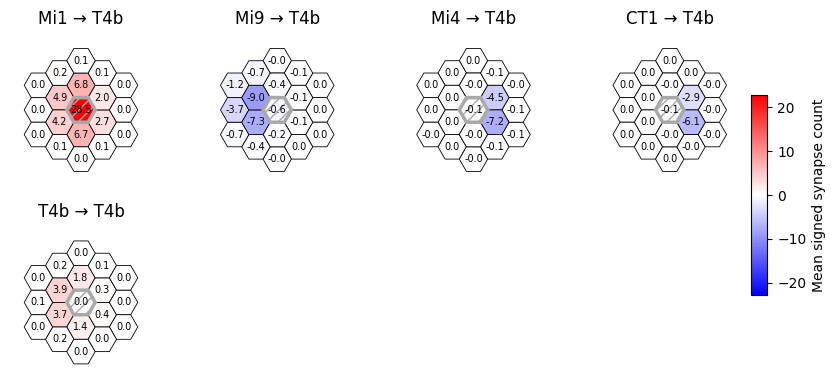

In [ ]:
receptive_fields_grid(kernels, value_col=VALUE_COL,input_types=input_types, post_type=POST_TYPE)

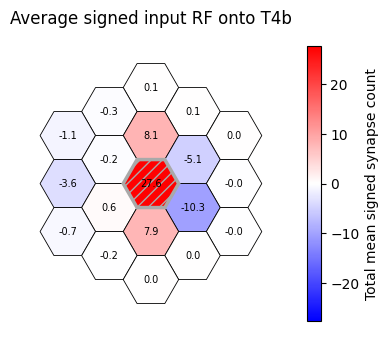

In [9]:
# Use either all input types, or the thresholded/sorted input_types from above
types_to_include = input_types  # thresholded list
# types_to_include = list(kernels.keys())  # all presynaptic types

avg_rf = (
    pd.concat(
        [
            kernels[pre_type][["dp", "dq", VALUE_COL]].assign(pre_cell_type=pre_type)
            for pre_type in types_to_include
        ],
        ignore_index=True
    )
    .groupby(["dp", "dq"], as_index=False)
    .agg(total_mean_signed_count=(VALUE_COL, "sum"))
)

from matplotlib.colors import TwoSlopeNorm

rf_value_col = "total_mean_signed_count"

vmax = np.nanmax(np.abs(avg_rf[rf_value_col]))

norm = TwoSlopeNorm(
    vmin=-vmax,
    vcenter=0,
    vmax=vmax
)

fig, ax = plt.subplots(figsize=(4, 4))

plot_spatial_kernel_hex(
    avg_rf,
    value_col=rf_value_col,
    radius=2,
    cmap="bwr",
    norm=norm,
    ax=ax,
    title=f"Average signed input RF onto {POST_TYPE}",
    plot_labels=True,
    use_input_relative_to_target=True,
    mirror_x=True,
    mirror_y=True,
)

ax.axis("off")

sm = plt.cm.ScalarMappable(norm=norm, cmap=plt.get_cmap("bwr"))
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    shrink=0.75,
    label="Total mean signed synapse count"
)

plt.tight_layout()
plt.show()